# Accidentologie routière en Tunisie (2001-2025) : géographie, rythme horaire et sévérité

**Source.** Extraction de l'Observatoire National de la Sécurité Routière (ONSR) : une ligne par accident corporel, du 1ᵉʳ janvier 2001 au 9 septembre 2026, avec la date, l'heure, le gouvernorat, le type d'accident, la cause, le nombre de tués et de blessés.

**Question de recherche.** Plutôt que de couvrir l'ensemble des dimensions du fichier, cette étude se concentre sur trois axes croisés :

1. **Où** les accidents se produisent-ils, et où sont-ils les plus meurtriers ? (répartition géographique par gouvernorat et par district)
2. **Quand**, dans la journée, le risque est-il le plus élevé ? (répartition par tranche horaire)
3. **À gravité égale, la part de victimes qui décèdent varie-t-elle** selon le lieu et l'heure ? (ratio tués / blessés, ou « taux de létalité »)

Les axes calendaires (mois, jour de semaine), la typologie des causes et des véhicules, ainsi que les modèles actuariels (GLM, modèle collectif, crédibilité) ne sont pas traités ici : ce n'est pas l'objet de ce travail.

**Plan**

1. Préparation des données
2. Statistiques descriptives
3. Axe 1 — Répartition géographique
4. Axe 2 — Rythme horaire
5. Axe 3 — Le ratio tués / blessés
6. Croisement géographie × horaire × létalité
7. Synthèse

**Exécution.** Place le fichier `accidents_routiers_tunisie_2001_2026.xlsx` dans un dossier `data/`. Librairies : `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`.

In [4]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

In [5]:
# --- Palette et thème (seaborn, distincts du gabarit de départ) -----------
PALETTE_DISTRICTS = "flare"                 # rampe séquentielle pour les régions
COULEUR_PRINCIPALE = "#0f6e6e"               # sarcelle
COULEUR_ACCENT = "#c9622a"                   # brique
COULEUR_NEUTRE = "#5b5b5b"

sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.0)
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 100,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def frnum(x, dec=1):
    '''Affiche un nombre au format français (virgule décimale, espace pour les milliers).'''
    if pd.isna(x):
        return "–"
    return f"{x:,.{dec}f}".replace(",", " ").replace(".", ",")

## 1. Préparation des données

Le fichier source utilise des en-têtes en arabe et du texte libre saisi à la main. La préparation ci-dessous ne conserve que ce qui sert directement aux trois axes retenus : elle est volontairement plus courte qu'une préparation exhaustive du jeu de données.

In [6]:
CHEMIN_FICHIER = Path("data") / "accidents_routiers_tunisie_2001_2026.xlsx"

brut = pd.read_excel(CHEMIN_FICHIER, dtype=str)
print(f"{len(brut):,} lignes brutes, {brut.shape[1]} colonnes".replace(",", " "))
brut.head(3)

211 268 lignes brutes  16 colonnes


,رقم الحادث,التاريخ,السنة,الشهر,اليوم,تاريخ_كامل,الولاية,مكان الحادث,كلم,نوع الحادث,الاسباب,الساعة,قتلى,جرحى,مرجع نظر,المعتمدية
0,148012,1,2012,جانفي,الاحد,01/01/2012 00:00:00,اريانة,جامع الروضة,-1,شاحنة بحاجز,السرعة,0,0,2,شرطة,NaN
1,148013,7,2012,جانفي,الثلاثاء,07/01/2012 00:00:00,قابس,شارع ابو القاسم الشابي,-1,سيارة بدراجة نارية,السهو وعدم الانتباه,18,0,1,شرطة,NaN
2,148014,7,2012,جانفي,الثلاثاء,07/01/2012 00:00:00,سليانة,الكريب,-1,سيارة بمترجل,شق الطريق,12,0,1,شرطة,NaN


In [7]:
# Correspondance des en-têtes arabes -> noms de travail
ENTETES = {
    "رقم الحادث": "id", "تاريخ_كامل": "date_brute", "الولاية": "gouvernorat_ar",
    "الساعة": "heure_brute", "قتلى": "tues_brut", "جرحى": "blesses_brut",
    "مرجع نظر": "autorite_ar",
}

df = brut.rename(columns=lambda c: ENTETES.get(str(c).strip(), c))[list(ENTETES.values())].copy()

df["date"] = pd.to_datetime(df["date_brute"], format="%d/%m/%Y %H:%M:%S", errors="coerce")
df["heure"] = pd.to_numeric(df["heure_brute"], errors="coerce")
df["tues"] = pd.to_numeric(df["tues_brut"], errors="coerce")
df["blesses"] = pd.to_numeric(df["blesses_brut"], errors="coerce")
df["annee"] = df["date"].dt.year

print(f"Dates illisibles : {df['date'].isna().sum()}  |  Heures hors 0-23 : {(~df['heure'].between(0, 23)).sum()}")

Dates illisibles : 0  |  Heures hors 0-23 : 0


In [8]:
# Gouvernorat (arabe -> français) et district INS de rattachement (5 districts)
GOUVERNORATS = {
    "بنزرت": ("Bizerte", "Nord"), "باجة": ("Béja", "Nord"), "جندوبة": ("Jendouba", "Nord"), "الكاف": ("Le Kef", "Nord"),
    "تونس": ("Tunis", "Grand Tunis"), "اريانة": ("Ariana", "Grand Tunis"), "بنعروس": ("Ben Arous", "Grand Tunis"),
    "منوبة": ("Manouba", "Grand Tunis"),
    "نابل": ("Nabeul", "Centre-Est"), "زغوان": ("Zaghouan", "Centre-Est"), "سوسة": ("Sousse", "Centre-Est"),
    "المنستير": ("Monastir", "Centre-Est"), "المهدية": ("Mahdia", "Centre-Est"), "صفاقس": ("Sfax", "Centre-Est"),
    "القصرين": ("Kasserine", "Centre-Ouest"), "القيروان": ("Kairouan", "Centre-Ouest"), "سليانة": ("Siliana", "Centre-Ouest"),
    "قفصة": ("Gafsa", "Centre-Ouest"),
    "سيدي بوزيد": ("Sidi Bouzid", "Sud"), "توزر": ("Tozeur", "Sud"), "قابس": ("Gabès", "Sud"),
    "مدنين": ("Médenine", "Sud"), "تطاوين": ("Tataouine", "Sud"), "قبلي": ("Kébili", "Sud"),
}
df["gouvernorat"] = df["gouvernorat_ar"].str.strip().map(lambda k: GOUVERNORATS.get(k, (None, None))[0])
df["district"] = df["gouvernorat_ar"].str.strip().map(lambda k: GOUVERNORATS.get(k, (None, None))[1])

# Milieu urbain / interurbain, approximé par l'autorité intervenante
df["milieu"] = np.where(df["autorite_ar"].str.strip() == "شرطة", "Urbain (police)", "Interurbain (garde nationale)")

df["jour_semaine"] = df["date"].dt.day_name(locale="fr_FR") if False else df["date"].dt.dayofweek
JOURS = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
df["jour_semaine"] = pd.Categorical(df["jour_semaine"].map(dict(enumerate(JOURS))), categories=JOURS, ordered=True)
df["week_end"] = df["jour_semaine"].isin(["Samedi", "Dimanche"])

avant = len(df)
df = df.dropna(subset=["date", "gouvernorat", "heure"])
df = df[(df["tues"] + df["blesses"]) > 0]              # on ne garde que les accidents avec au moins une victime
df = df[df["annee"].between(2001, 2025)]                 # années pleines uniquement (2026 est partielle)
print(f"{avant - len(df):,} lignes écartées (gouvernorat/date/heure manquants, sans victime, ou année 2026) → {len(df):,} accidents retenus".replace(",", " "))

3 227 lignes écartées (gouvernorat/date/heure manquants  sans victime  ou année 2026) → 208 041 accidents retenus


In [9]:
# Tranches horaires : découpage en 6 blocs de 4 heures (granularité différente d'un découpage classique en 4 périodes)
BORNES_HORAIRES = [-1, 3, 7, 11, 15, 19, 23]
LIBELLES_HORAIRES = ["00h-03h", "04h-07h", "08h-11h", "12h-15h", "16h-19h", "20h-23h"]
df["tranche_horaire"] = pd.cut(df["heure"], bins=BORNES_HORAIRES, labels=LIBELLES_HORAIRES, ordered=True)

# Variables de sévérité
df["victimes"] = df["tues"] + df["blesses"]
df["mortel"] = df["tues"] > 0
# Taux de létalité : part des victimes d'un accident qui sont décédées (0-100, bien défini même si blesses = 0)
df["taux_letalite"] = 100 * df["tues"] / df["victimes"]
# Ratio brut, pour l'intuition : nombre de tués pour 1 blessé (NaN si aucun blessé)
df["ratio_tues_blesses"] = df["tues"] / df["blesses"].replace(0, np.nan)

df[["gouvernorat", "district", "tranche_horaire", "tues", "blesses", "taux_letalite"]].head()

,gouvernorat,district,tranche_horaire,tues,blesses,taux_letalite
0,Ariana,Grand Tunis,00h-03h,0,2,0.0
1,Gabès,Sud,16h-19h,0,1,0.0
2,Siliana,Centre-Ouest,12h-15h,0,1,0.0
3,Sfax,Centre-Est,12h-15h,0,1,0.0
4,Ben Arous,Grand Tunis,16h-19h,0,3,0.0


## 2. Statistiques descriptives:

Avant de descendre dans les trois axes, un aperçu d'ensemble : la distribution des tués et des blessés par accident, et la façon dont les variables numériques se corrèlent entre elles.

In [10]:
stats_descr = df[["tues", "blesses", "victimes", "taux_letalite", "heure"]].agg(
    ["count", "mean", "std", "min", "median", "max", "skew"]
).T
stats_descr.columns = ["n", "moyenne", "écart-type", "min", "médiane", "max", "asymétrie (skew)"]
stats_descr.round(2)

,n,moyenne,écart-type,min,médiane,max,asymétrie (skew)
tues,208041.0,0.17,0.46,0.0,0.0,30.0,5.63
blesses,208041.0,1.42,1.46,0.0,1.0,132.0,15.87
victimes,208041.0,1.58,1.50,1.0,1.0,133.0,15.91
taux_letalite,208041.0,11.11,29.39,0.0,0.0,100.0,2.49
heure,208041.0,13.69,5.48,0.0,14.0,23.0,-0.40


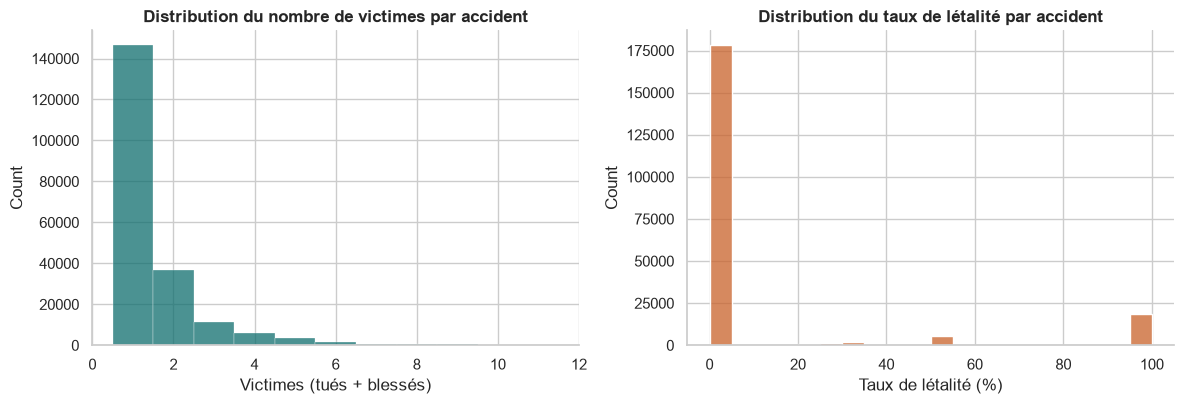

93.5 % des accidents comptent 3 victimes ou moins.
14.4 % des accidents font au moins un tué.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

sns.histplot(df["victimes"], discrete=True, color=COULEUR_PRINCIPALE, ax=axes[0])
axes[0].set_xlim(0, 12)
axes[0].set_title("Distribution du nombre de victimes par accident")
axes[0].set_xlabel("Victimes (tués + blessés)")

sns.histplot(df["taux_letalite"], bins=20, color=COULEUR_ACCENT, ax=axes[1])
axes[1].set_title("Distribution du taux de létalité par accident")
axes[1].set_xlabel("Taux de létalité (%)")

fig.tight_layout()
plt.show()

print(f"{100 * (df['victimes'] <= 3).mean():.1f} % des accidents comptent 3 victimes ou moins.")
print(f"{100 * df['mortel'].mean():.1f} % des accidents font au moins un tué.")

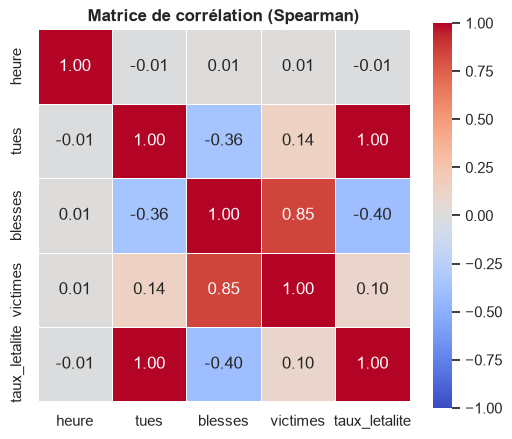

,heure,tues,blesses,victimes,taux_letalite
heure,1.00,-0.01,0.01,0.01,-0.01
tues,-0.01,1.00,-0.36,0.14,1.00
blesses,0.01,-0.36,1.00,0.85,-0.40
victimes,0.01,0.14,0.85,1.00,0.10
taux_letalite,-0.01,1.00,-0.40,0.10,1.00


In [12]:
variables_numeriques = ["heure", "tues", "blesses", "victimes", "taux_letalite"]
correlations = df[variables_numeriques].corr(method="spearman")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Matrice de corrélation (Spearman)")
plt.show()

correlations.round(2)

**Lecture.** Le nombre de tués et de blessés par accident est très asymétrique (la moyenne est tirée vers le haut par une minorité d'accidents collectifs) : c'est pourquoi la matrice utilise une corrélation de Spearman (sur les rangs) plutôt que de Pearson, moins sensible à cette asymétrie. Distribution très asymétrique (93,5% des accidents ≤3 victimes) → Spearman justifié. tues~taux_letalite = 1,00 est trivial (calculé l'un à partir de l'autre, à ne pas citer comme résultat). tues et blesses corrélés négativement (ρ=-0,36) : deux régimes d'accidents distincts. heure non corrélée (|ρ|≤0,01) car la relation horaire est en U, pas monotone.

## 3. Axe 1 — Répartition géographique

On agrège par gouvernorat puis par district (regroupement des gouvernorats en 5 grandes régions). Deux angles : le **volume** (où se produisent les accidents) et la **létalité** (où sont-ils les plus mortels, à nombre d'accidents égal).

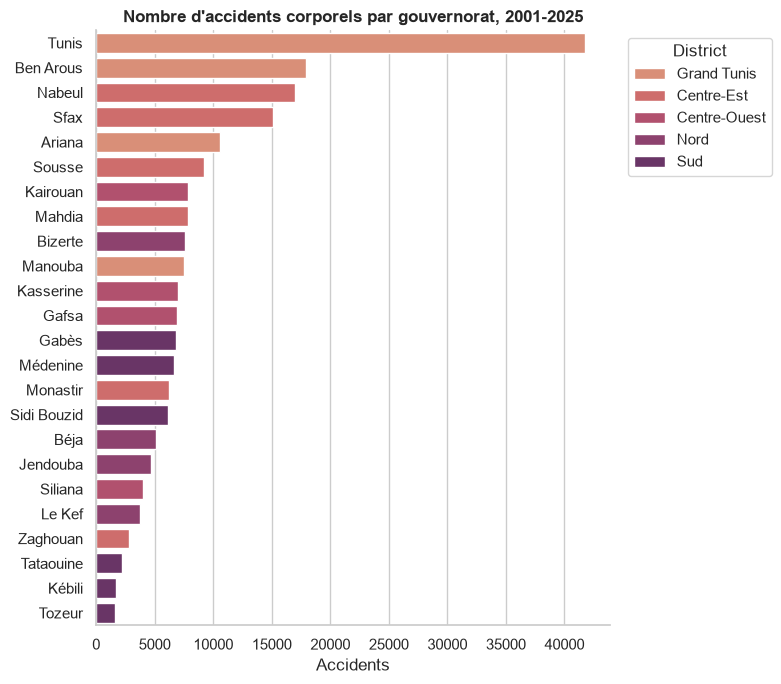

In [13]:
par_gouvernorat = df.groupby("gouvernorat").agg(
    accidents=("id", "size"), tues=("tues", "sum"), blesses=("blesses", "sum"),
    district=("district", "first"),
)
par_gouvernorat["taux_letalite"] = 100 * par_gouvernorat["tues"] / (par_gouvernorat["tues"] + par_gouvernorat["blesses"])
par_gouvernorat = par_gouvernorat.sort_values("accidents", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=par_gouvernorat.reset_index(), y="gouvernorat", x="accidents",
            hue="district", dodge=False, palette=PALETTE_DISTRICTS, ax=ax)
ax.set_title("Nombre d'accidents corporels par gouvernorat, 2001-2025")
ax.set_xlabel("Accidents")
ax.set_ylabel("")
ax.legend(title="District", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

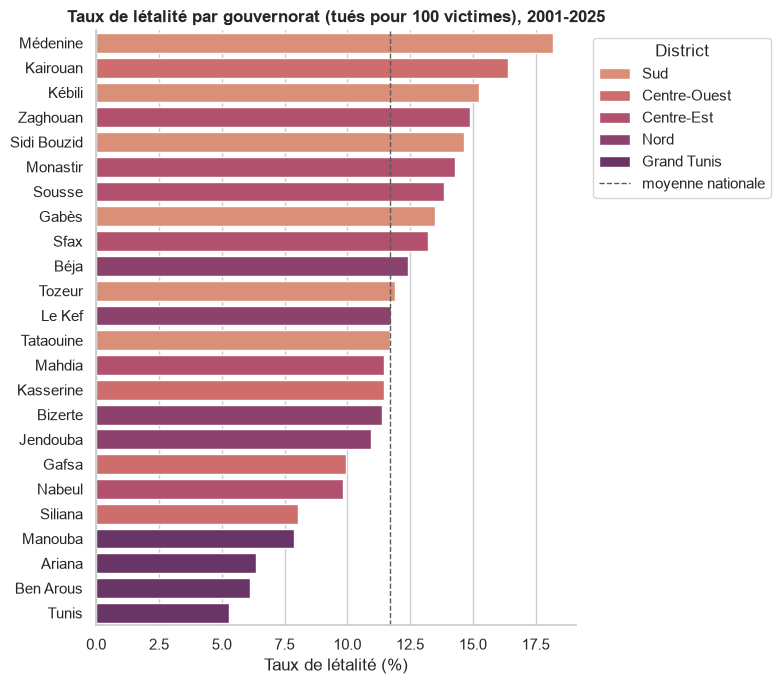

In [14]:
classement_letalite = par_gouvernorat.sort_values("taux_letalite", ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
sns.barplot(data=classement_letalite.reset_index(), y="gouvernorat", x="taux_letalite",
            hue="district", dodge=False, palette=PALETTE_DISTRICTS, ax=ax)
ax.axvline(par_gouvernorat["taux_letalite"].mean(), color=COULEUR_NEUTRE, ls="--", lw=1,
           label="moyenne nationale")
ax.set_title("Taux de létalité par gouvernorat (tués pour 100 victimes), 2001-2025")
ax.set_xlabel("Taux de létalité (%)")
ax.set_ylabel("")
ax.legend(title="District", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [15]:
par_district = df.groupby("district").agg(
    accidents=("id", "size"), tues=("tues", "sum"), blesses=("blesses", "sum"),
)
par_district["taux_letalite"] = 100 * par_district["tues"] / (par_district["tues"] + par_district["blesses"])
par_district["part_accidents (%)"] = 100 * par_district["accidents"] / par_district["accidents"].sum()
par_district["part_tues (%)"] = 100 * par_district["tues"] / par_district["tues"].sum()
par_district = par_district.sort_values("taux_letalite", ascending=False)
par_district.round(1)

,accidents,tues,blesses,taux_letalite,part_accidents (%),part_tues (%)
district,,,,,,
Sud,25106,6442,36733,14.9,12.1,18.7
Centre-Est,58121,12026,85359,12.3,27.9,34.9
Centre-Ouest,25766,5381,38856,12.2,12.4,15.6
Nord,21207,4164,31619,11.6,10.2,12.1
Grand Tunis,77841,6424,102674,5.9,37.4,18.7


In [16]:
# Le district influence-t-il le fait qu'un accident soit mortel ? Test du chi² d'indépendance
contingence_district = pd.crosstab(df["district"], df["mortel"])
chi2_d, p_d, ddl_d, _ = stats.chi2_contingency(contingence_district)
n_d = contingence_district.to_numpy().sum()
v_cramer_d = np.sqrt(chi2_d / (n_d * (min(contingence_district.shape) - 1)))

print(f"Chi² d'indépendance district × accident mortel : chi2 = {chi2_d:.1f}, ddl = {ddl_d}, "
      f"p = {p_d:.4f}, V de Cramér = {v_cramer_d:.3f}")

Chi² d'indépendance district × accident mortel : chi2 = 4900.6, ddl = 4, p = 0.0000, V de Cramér = 0.153


Tunis = 1er en volume (~42 000), mais létalité basse (~5,3%). Médenine = 1er en létalité (~18,3%) mais faible volume. Grand Tunis : 37,4% des accidents, 5,9% de létalité (la plus basse). Sud : 12,1% des accidents mais 14,9% de létalité (la plus haute). Chi² significatif mais modeste (χ²=4900,6, p<0,001, V=0,153).

## 4. Axe 2 — Rythme horaire

Répartition des accidents sur les 6 tranches horaires définies en section 1, et croisement avec le jour de la semaine (semaine / week-end).

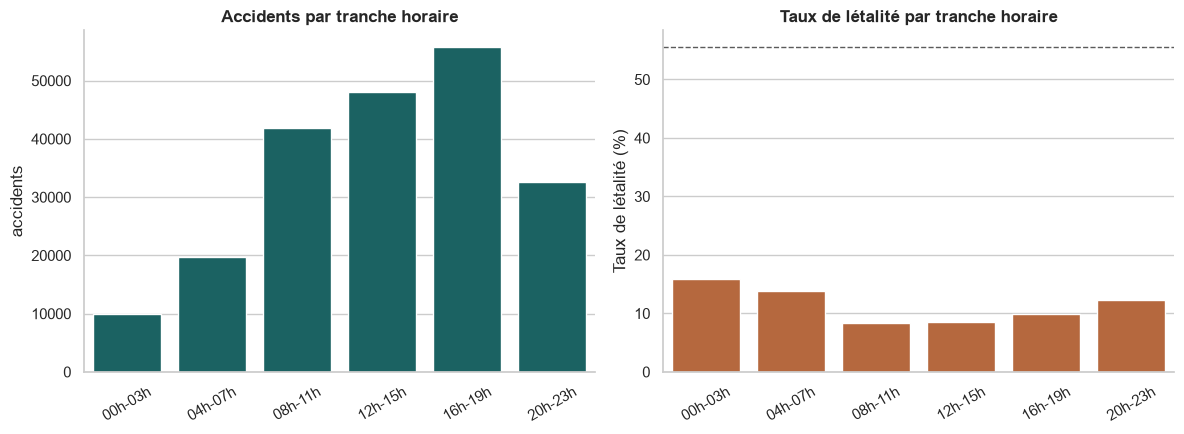

,accidents,tues,blesses,taux_letalite,part_accidents (%)
tranche_horaire,,,,,
00h-03h,9920,3065,16329,15.8,4.8
04h-07h,19779,4919,30630,13.8,9.5
08h-11h,41842,5140,56637,8.3,20.1
12h-15h,48107,6193,66456,8.5,23.1
16h-19h,55823,8448,77539,9.8,26.8
20h-23h,32570,6672,47650,12.3,15.7


In [17]:
par_tranche = df.groupby("tranche_horaire", observed=True).agg(
    accidents=("id", "size"), tues=("tues", "sum"), blesses=("blesses", "sum"),
)
par_tranche["taux_letalite"] = 100 * par_tranche["tues"] / (par_tranche["tues"] + par_tranche["blesses"])
par_tranche["part_accidents (%)"] = 100 * par_tranche["accidents"] / par_tranche["accidents"].sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

sns.barplot(data=par_tranche.reset_index(), x="tranche_horaire", y="accidents",
            color=COULEUR_PRINCIPALE, ax=ax1)
ax1.set_title("Accidents par tranche horaire")
ax1.set_xlabel("")
ax1.tick_params(axis="x", rotation=30)

sns.barplot(data=par_tranche.reset_index(), x="tranche_horaire", y="taux_letalite",
            color=COULEUR_ACCENT, ax=ax2)
ax2.axhline(df["mortel"].pipe(lambda s: 100 * df.loc[s, "tues"].sum() / df.loc[s, "victimes"].sum()),
            color=COULEUR_NEUTRE, ls="--", lw=1)
ax2.set_title("Taux de létalité par tranche horaire")
ax2.set_ylabel("Taux de létalité (%)")
ax2.set_xlabel("")
ax2.tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()

par_tranche.round(1)

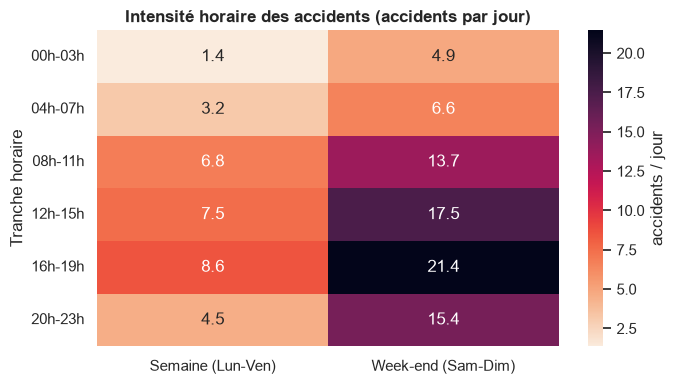

In [18]:
# Volume d'accidents : tranche horaire x semaine/week-end
volume_horaire = df.pivot_table(index="tranche_horaire", columns="week_end", values="id",
                                 aggfunc="size", observed=True)
volume_horaire.columns = ["Semaine (Lun-Ven)", "Week-end (Sam-Dim)"]
# Normalisation par jour : 5 jours de semaine, 2 jours de week-end sur la période complète
nb_jours_semaine = df.loc[~df["week_end"], "date"].dt.date.nunique() * 5 / 7
nb_jours_weekend = df.loc[df["week_end"], "date"].dt.date.nunique() * 2 / 7
intensite_horaire = volume_horaire.div([nb_jours_semaine, nb_jours_weekend], axis=1)

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(intensite_horaire, annot=True, fmt=".1f", cmap="rocket_r", ax=ax,
            cbar_kws={"label": "accidents / jour"})
ax.set_title("Intensité horaire des accidents (accidents par jour)")
ax.set_xlabel("")
ax.set_ylabel("Tranche horaire")
plt.tight_layout()
plt.show()

In [19]:
# La tranche horaire influence-t-elle la létalité ? Kruskal-Wallis sur le taux de létalité par accident
groupes_horaires = [g["taux_letalite"].dropna().to_numpy() for _, g in df.groupby("tranche_horaire", observed=True)]
h_stat, p_kw = stats.kruskal(*groupes_horaires)
print(f"Test de Kruskal-Wallis (taux de létalité ~ tranche horaire) : H = {h_stat:.1f}, p = {p_kw:.4f}")

contingence_horaire = pd.crosstab(df["tranche_horaire"], df["mortel"])
chi2_h, p_h, ddl_h, _ = stats.chi2_contingency(contingence_horaire)
print(f"Chi² (tranche horaire × accident mortel) : chi2 = {chi2_h:.1f}, ddl = {ddl_h}, p = {p_h:.4f}")

Test de Kruskal-Wallis (taux de létalité ~ tranche horaire) : H = 2782.2, p = 0.0000
Chi² (tranche horaire × accident mortel) : chi2 = 2932.0, ddl = 5, p = 0.0000


- Le volume se joue en journée. La tranche 16h-19h concentre le plus d'accidents (55 823, soit 26,8 % du total), suivie de 12h-15h (23,1 %) et 08h-11h (20,1 %) : à elles trois, les tranches diurnes (08h-19h) totalisent 70 % des accidents, cohérent avec la densité de circulation en journée. 

- La létalité s'inverse la nuit. Elle est maximale sur 00h-03h (15,8 %) et 04h-07h (13,8 %) — près du double des tranches les plus sûres, 08h-11h (8,3 %) et 12h-15h (8,5 %). La tranche 20h-23h renoue avec une létalité plus élevée (12,3 %). 

- Ce profil est statistiquement net. Le test de Kruskal-Wallis rejette fortement l'hypothèse d'une létalité identique entre tranches ($H = 2\,782{,}2$ ; $p < 0{,}001$), confirmé par le $\chi^2$ tranche horaire $\times$ accident mortel ($\chi^2 = 2\,932{,}0$ ; $ddl = 5$ ; $p < 0{,}001$). 

- Volume et létalité sont donc décorrélés dans le temps aussi, comme ils l'étaient dans l'espace (section 3) : les tranches les plus chargées (12h-19h) sont les moins létales, et inversement la nuit — probablement un effet de vitesse (trafic plus fluide) et de délai de détection/secours.

## 5. Axe 3 — Le ratio tués / blessés

On approfondit ici la variable centrale des deux sections précédentes : le **taux de létalité** (tués pour 100 victimes), complété par le ratio brut tués/blessés pour l'intuition, et sa relation avec le milieu (urbain / interurbain).

In [20]:
print(f"Au niveau national : {df['tues'].sum():,.0f} tués pour {df['blesses'].sum():,.0f} blessés "
      f"(1 tué pour {df['blesses'].sum() / df['tues'].sum():.1f} blessés), "
      f"soit un taux de létalité de {100 * df['tues'].sum() / df['victimes'].sum():.1f} %.".replace(",", " "))

Au niveau national : 34 437 tués pour 295 241 blessés (1 tué pour 8.6 blessés)  soit un taux de létalité de 10.4 %.


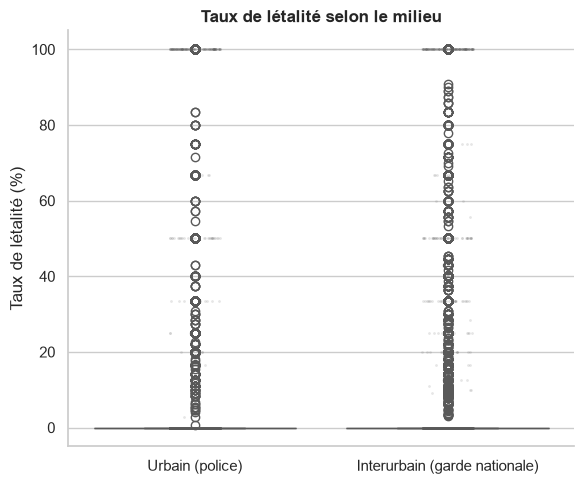

Test de Mann-Whitney (létalité, urbain vs interurbain) : U = 4278884008, p = 0.0000
Létalité médiane — urbain : 0.0 % | interurbain : 0.0 %


In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="milieu", y="taux_letalite", hue="milieu", palette="Set2", legend=False, ax=ax)
sns.stripplot(data=df.sample(min(3000, len(df)), random_state=0), x="milieu", y="taux_letalite",
              color=COULEUR_NEUTRE, alpha=0.15, size=2, ax=ax)
ax.set_title("Taux de létalité selon le milieu")
ax.set_xlabel("")
ax.set_ylabel("Taux de létalité (%)")
plt.tight_layout()
plt.show()

urbain = df.loc[df["milieu"] == "Urbain (police)", "taux_letalite"].dropna()
interurbain = df.loc[df["milieu"] == "Interurbain (garde nationale)", "taux_letalite"].dropna()
u_stat, p_u = stats.mannwhitneyu(urbain, interurbain, alternative="two-sided")
print(f"Test de Mann-Whitney (létalité, urbain vs interurbain) : U = {u_stat:.0f}, p = {p_u:.4f}")
print(f"Létalité médiane — urbain : {urbain.median():.1f} % | interurbain : {interurbain.median():.1f} %")

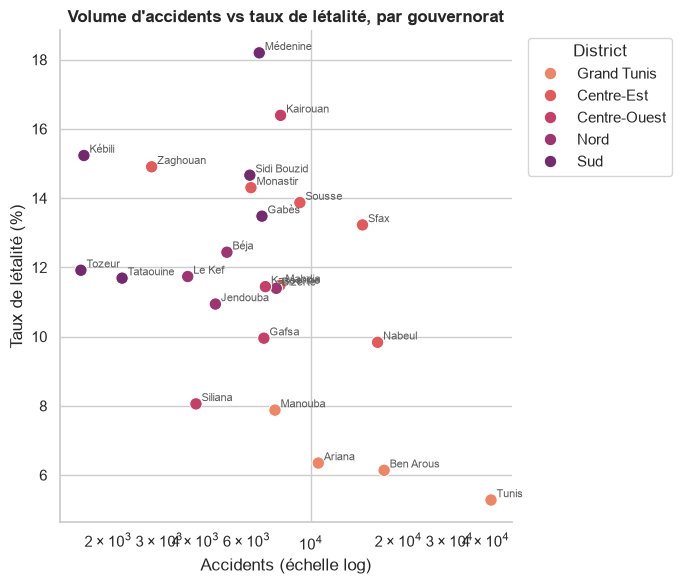

In [22]:
top10_letalite = par_gouvernorat.nlargest(10, "taux_letalite")
top10_volume = par_gouvernorat.nlargest(10, "accidents")

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=par_gouvernorat.reset_index(), x="accidents", y="taux_letalite",
                 hue="district", palette=PALETTE_DISTRICTS, s=80, ax=ax)
for gouvernorat, ligne in par_gouvernorat.iterrows():
    ax.annotate(gouvernorat, (ligne["accidents"], ligne["taux_letalite"]),
                fontsize=8, xytext=(4, 2), textcoords="offset points", color=COULEUR_NEUTRE)
ax.set_xscale("log")
ax.set_title("Volume d'accidents vs taux de létalité, par gouvernorat")
ax.set_xlabel("Accidents (échelle log)")
ax.set_ylabel("Taux de létalité (%)")
ax.legend(title="District", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

- Au niveau national, 34 437 tués pour 295 241 blessés, soit 1 tué pour 8,6 blessés et un taux de létalité de 10,4 %. 

- La comparaison urbain/interurbain par la médiane n'est pas informative ici : les deux médianes valent 0 %, parce que 85,6 % des accidents ne font aucun mort dans les deux milieux — le boxplot est donc écrasé contre zéro. Le test de Mann-Whitney détecte pourtant une différence significative de distribution ($U = 4\,278\,884\,008$ ; $p < 0{,}001$), portée par la partie haute de la distribution plutôt que par la médiane. 

- Le nuage de points volume $\times$ létalité par gouvernorat rend visible, à l'échelle individuelle, l'opposition déjà observée par district : les gouvernorats du Grand Tunis (Tunis, Ben Arous, Ariana, Manouba) se regroupent en bas à droite (volume élevé, létalité basse), tandis que ceux du Sud et du Centre-Ouest (Médenine, Kairouan, Kébili, Sidi Bouzid) se regroupent en haut à gauche (volume plus faible, létalité élevée). Cohérent avec un contraste route interurbaine / voirie urbaine : vitesses plus basses et secours plus proches en zone urbaine dense, contre un réseau plus interurbain où l'accident est plus rare mais plus souvent mortel.

## 6. Croisement géographie × horaire × létalité

Les deux premiers axes pris isolément : où, et quand. On les croise ici pour repérer les combinaisons district × tranche horaire les plus critiques en matière de létalité.

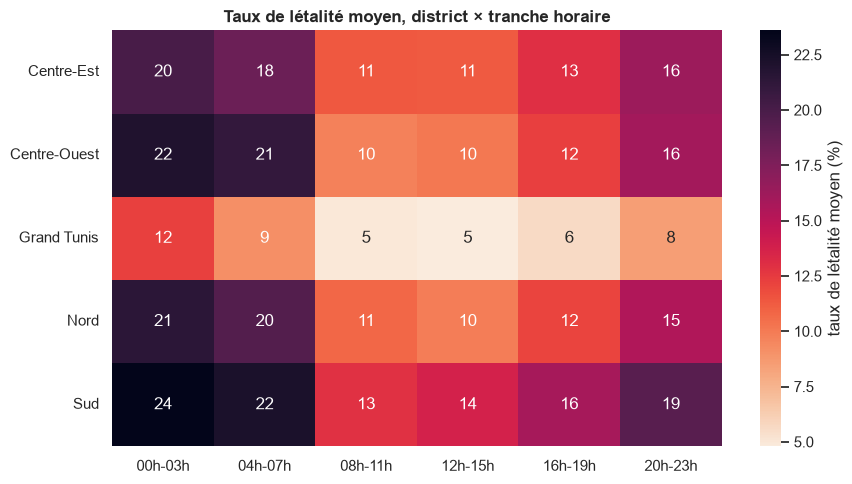

Effectifs sous-jacents à chaque case (à vérifier avant toute conclusion sur une case précise) :


tranche_horaire,00h-03h,04h-07h,08h-11h,12h-15h,16h-19h,20h-23h
district,,,,,,
Centre-Est,3305,5935,10459,13054,16112,9256
Centre-Ouest,1166,2167,5649,6043,6948,3793
Grand Tunis,3303,7340,16387,18277,20256,12278
Nord,841,1818,4246,5137,5828,3337
Sud,1305,2519,5101,5596,6679,3906


In [23]:
croisement = df.pivot_table(index="district", columns="tranche_horaire", values="taux_letalite",
                             aggfunc="mean", observed=True)
effectifs_croises = df.pivot_table(index="district", columns="tranche_horaire", values="id",
                                    aggfunc="size", observed=True)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(croisement, annot=True, fmt=".0f", cmap="rocket_r", ax=ax,
            cbar_kws={"label": "taux de létalité moyen (%)"})
ax.set_title("Taux de létalité moyen, district × tranche horaire")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

print("Effectifs sous-jacents à chaque case (à vérifier avant toute conclusion sur une case précise) :")
effectifs_croises

**Lecture.** Les effectifs sous-jacents à chaque case restent partout substantiels (minimum de 841 accidents, pour Nord × 00h-03h) : aucune case de ce tableau croisé ne repose sur un échantillon fragile, contrairement à ce qui pourrait se produire à une maille géographique plus fine (délégation). Les taux de létalité affichés sont donc directement interprétables, sans réserve liée à la taille de l'échantillon.

- **L'effet géographique persiste à toute heure.** Le Grand Tunis affiche la létalité la plus basse sur chacune des six tranches horaires (de 5 % en journée à 12 % la nuit), tandis que le Sud affiche la plus haute sur chacune d'entre elles (de 13 % en journée à 24 % la nuit). Le classement des districts ne se réorganise donc pas selon l'heure : district et tranche horaire semblent agir comme deux effets qui s'additionnent plutôt que comme deux facteurs qui s'annuleraient ou s'inverseraient l'un l'autre.
- **La combinaison la plus critique est le Sud en pleine nuit.** Sud × 00h-03h culmine à 24 % de létalité (1 305 accidents), suivi de Sud × 04h-07h à 22 % (2 519 accidents) — près du double de la moyenne nationale (10,4 %). C'est la seule zone du tableau où l'ensemble des tranches, y compris diurnes, se maintient au-dessus de 13 %, là où les autres districts descendent à 9-11 % en journée.
- **Le Grand Tunis reste protecteur même la nuit.** Sa case la plus défavorable (00h-03h, 12 %) demeure inférieure à la case la plus favorable de n'importe quel autre district (10 %, pour Centre-Ouest et Nord en journée).

C'est le Sud sur les tranches nocturnes qui justifierait le plus une action ciblée (contrôles renforcés, éclairage, signalisation) : effectif suffisant et létalité nettement supérieure au reste du tableau, sur la totalité des créneaux horaires et pas seulement ponctuellement.

## 7. Synthèse et limites

### Ce que ce travail couvre (et ne couvre pas)

Cette analyse s'est volontairement limitée à trois axes — géographie, tranches horaires, ratio tués/blessés — et à leur croisement, en laissant de côté le calendrier (mois, jour de la semaine pris isolément), la typologie des causes et des véhicules, ainsi que toute modélisation prédictive (fréquence, sévérité, crédibilité). Ce choix permet d'approfondir ces trois axes plutôt que de les traiter superficiellement parmi beaucoup d'autres.

### Principaux résultats

1. **Géographie.** Tunis concentre le plus grand volume d'accidents (≈ 42 000 sur 2001-2025), mais affiche l'un des taux de létalité les plus faibles du pays (≈ 5,3 %). À l'inverse, Médenine, loin derrière en volume, présente la létalité la plus élevée (≈ 18,3 %). Cette opposition se confirme au niveau des districts : le Grand Tunis totalise 37,4 % des accidents pour une létalité de 5,9 % (la plus basse), contre 12,1 % des accidents et 14,9 % de létalité (la plus haute) pour le Sud. L'association entre district et caractère mortel de l'accident est statistiquement significative mais d'intensité modeste (χ² = 4 900,6 ; ddl = 4 ; p < 0,001 ; V de Cramér = 0,153).
2. **Horaire.** Le volume d'accidents culmine en fin de journée, sur la tranche 16h-19h (55 823 accidents, 26,8 % du total). La létalité suit un profil inverse : maximale la nuit, sur 00h-03h (15,8 %), minimale en milieu de journée, sur 08h-11h (8,3 %). Cet écart est statistiquement net (test de Kruskal-Wallis : H = 2 782,2 ; p < 0,001).
3. **Ratio tués/blessés.** Le taux de létalité national s'établit à 10,4 % (soit un tué pour 8,6 blessés). La comparaison urbain/interurbain par la médiane n'est pas discriminante (0 % dans les deux cas, la majorité des accidents n'étant pas mortels), mais le test de Mann-Whitney révèle une différence de distribution significative entre les deux milieux (p < 0,001).
4. **Croisement.** L'effet géographique et l'effet horaire se cumulent plutôt qu'ils ne s'annulent : la combinaison la plus critique est le Sud en pleine nuit (00h-03h : 24 % de létalité ; 04h-07h : 22 %), tandis que le Grand Tunis reste sous la moyenne nationale à toute heure, y compris la nuit (12 % au plus).

### Limites

- **Exposition.** Le fichier ne renseigne ni la population ni le trafic par territoire : les écarts de volume entre gouvernorats reflètent en partie leur densité de population et l'importance de leur réseau routier, et pas seulement un niveau de risque intrinsèque.
- **Robustesse du croisement géographie × horaire.** Les effectifs par case restent partout substantiels (minimum 841 accidents), ce qui rend les taux de létalité du tableau croisé directement interprétables ; l'effet d'interaction entre district et tranche horaire, en revanche, n'a pas fait l'objet d'un test statistique formel et reste une lecture qualitative.
- **Champ.** Seuls les accidents corporels constatés sont recensés ; le milieu urbain/interurbain est approximé par l'autorité intervenante (police / garde nationale), une simplification qui n'est pas une donnée géographique directe.
- **Portée temporelle.** L'année 2026 est exclue car incomplète ; les résultats couvrent 2001-2025 sans isoler une éventuelle évolution récente, qui sort du champ retenu ici.